# 3. Vision Dataset Structure

## 1. Images

Images are the **visual inputs** provided to a computer vision model.

Examples:

- `.jpg`
- `.jpeg`
- `.png`

A dataset may contain:

```text
image_001.jpg
image_002.jpg
image_003.jpg
```

The image provides the raw visual information from which the model learns patterns such as shapes, textures, colors, edges, and spatial relationships.

---

## 2. Labels

A **label** describes what an image or object represents.

For image classification:

| Image | Label |
|---|---|
| `image_001.jpg` | Car |
| `image_002.jpg` | Dog |
| `image_003.jpg` | Cat |

Classification answers:

> **What is present?**

Example:

```text
Image → Model → "Dog"
```

---

## 3. Bounding Boxes

A **bounding box** identifies the location of an object inside an image.

Used mainly for **object detection**.

A bounding box can be represented as:

$$
(x_{\min}, y_{\min}, x_{\max}, y_{\max})
$$

or:

$$
(x_{center}, y_{center}, width, height)
$$

depending on the annotation format.

### Detection provides:

```text
What?  → Car
Where? → Bounding box
```

Therefore:

> **Object Detection = What + Where**

---

## 4. Masks

A **mask** identifies the pixels belonging to an object or region.

Masks are used in **image segmentation**.

Conceptually:

```text
0 → Background
1 → Object
```

Example:

```text
0 0 0 0 0
0 0 1 0 0
0 1 1 1 0
0 1 0 1 0
0 0 0 0 0
```

Unlike a bounding box, a mask can follow the actual shape and boundary of an object.

> **Segmentation = Which pixels belong to the object/region?**

---

## 5. Classification vs Detection vs Segmentation

| Task | Annotation | Answers |
|---|---|---|
| Classification | Label | What? |
| Detection | Label + Bounding Box | What + Where? |
| Segmentation | Label + Mask | What + Which Pixels? |

```text
Classification
      ↓
     WHAT?

Detection
      ↓
WHAT + WHERE?

Segmentation
      ↓
WHAT + WHICH PIXELS?
```

---

## 6. Train / Validation / Test

A vision dataset is usually divided into separate subsets.

```text
Dataset
   │
   ├── Training
   ├── Validation
   └── Test
```

### Training Set

Used to **learn model parameters**.

```text
Training Images + Labels
          ↓
       Model
          ↓
   Learns patterns
```

### Validation Set

Used during development for decisions such as:

- Hyperparameter tuning
- Model comparison
- Threshold selection
- Architecture selection
- Early stopping

### Test Set

Used for **final evaluation** after model-development decisions are complete.

### Mental model

```text
Train
  ↓
Learn

Validation
  ↓
Choose / Tune

Test
  ↓
Final Evaluation
```

> The test set should represent **unseen data** so that we can measure generalization.

---

## 7. Class Imbalance

**Class imbalance** occurs when some classes have substantially more examples than others.

Example:

| Class | Number of Images |
|---|---:|
| Dog | 8,000 |
| Cat | 1,500 |
| Tiger | 100 |

Here, the dataset is highly imbalanced.

### Problem

A model may become biased toward majority classes because it sees them much more frequently.

Accuracy can also become misleading.

Example:

```text
990 normal images
10 defective images
```

A model that predicts:

```text
Everything → Normal
```

achieves:

$$
Accuracy = \frac{990}{1000} = 99\%
$$

but detects:

```text
0 / 10 defective images
```

Therefore:

> **High accuracy does not necessarily mean a useful model.**

For imbalanced problems, metrics such as **precision, recall, and F1-score** may provide more useful information.

---

## 8. Annotation Quality

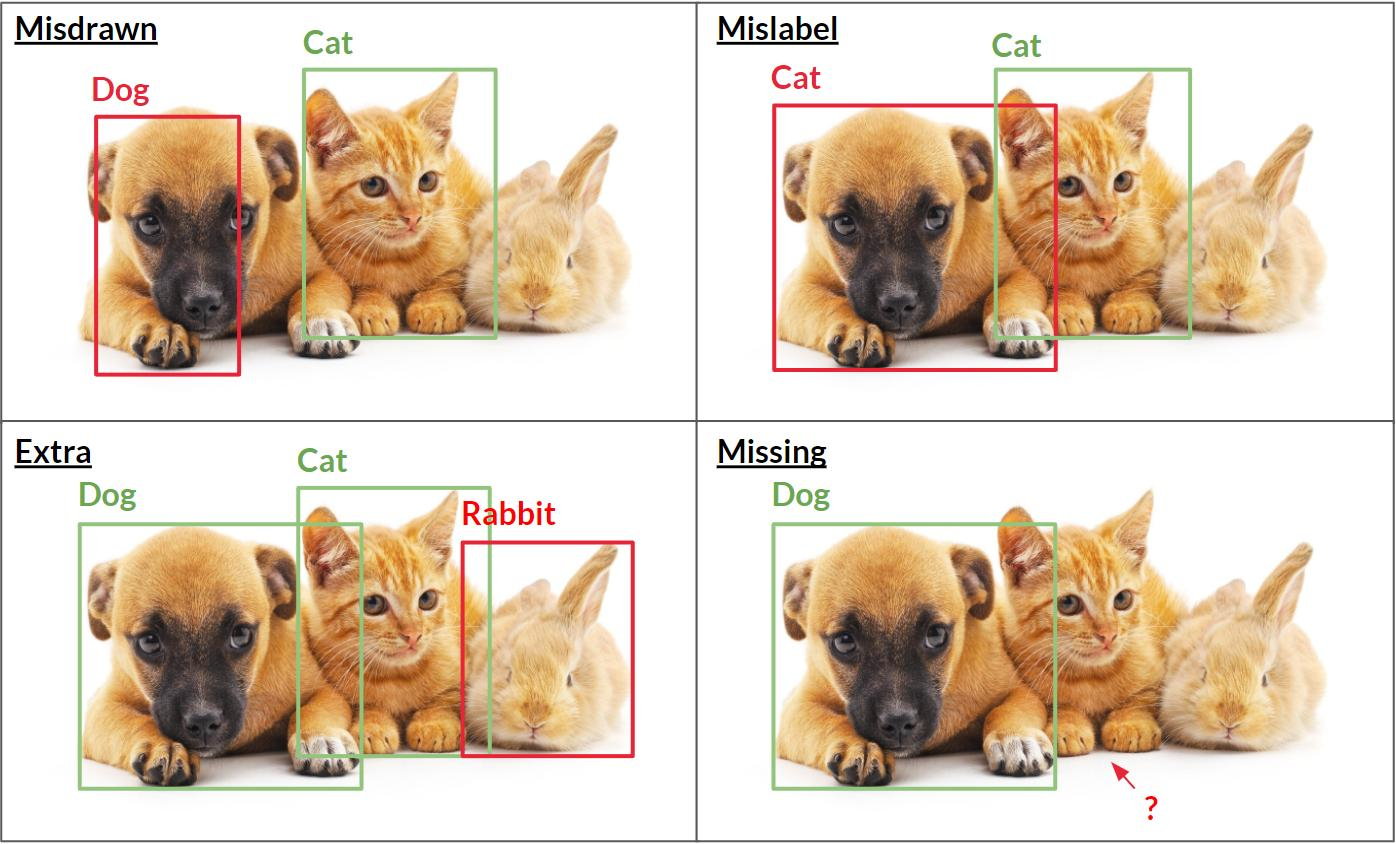

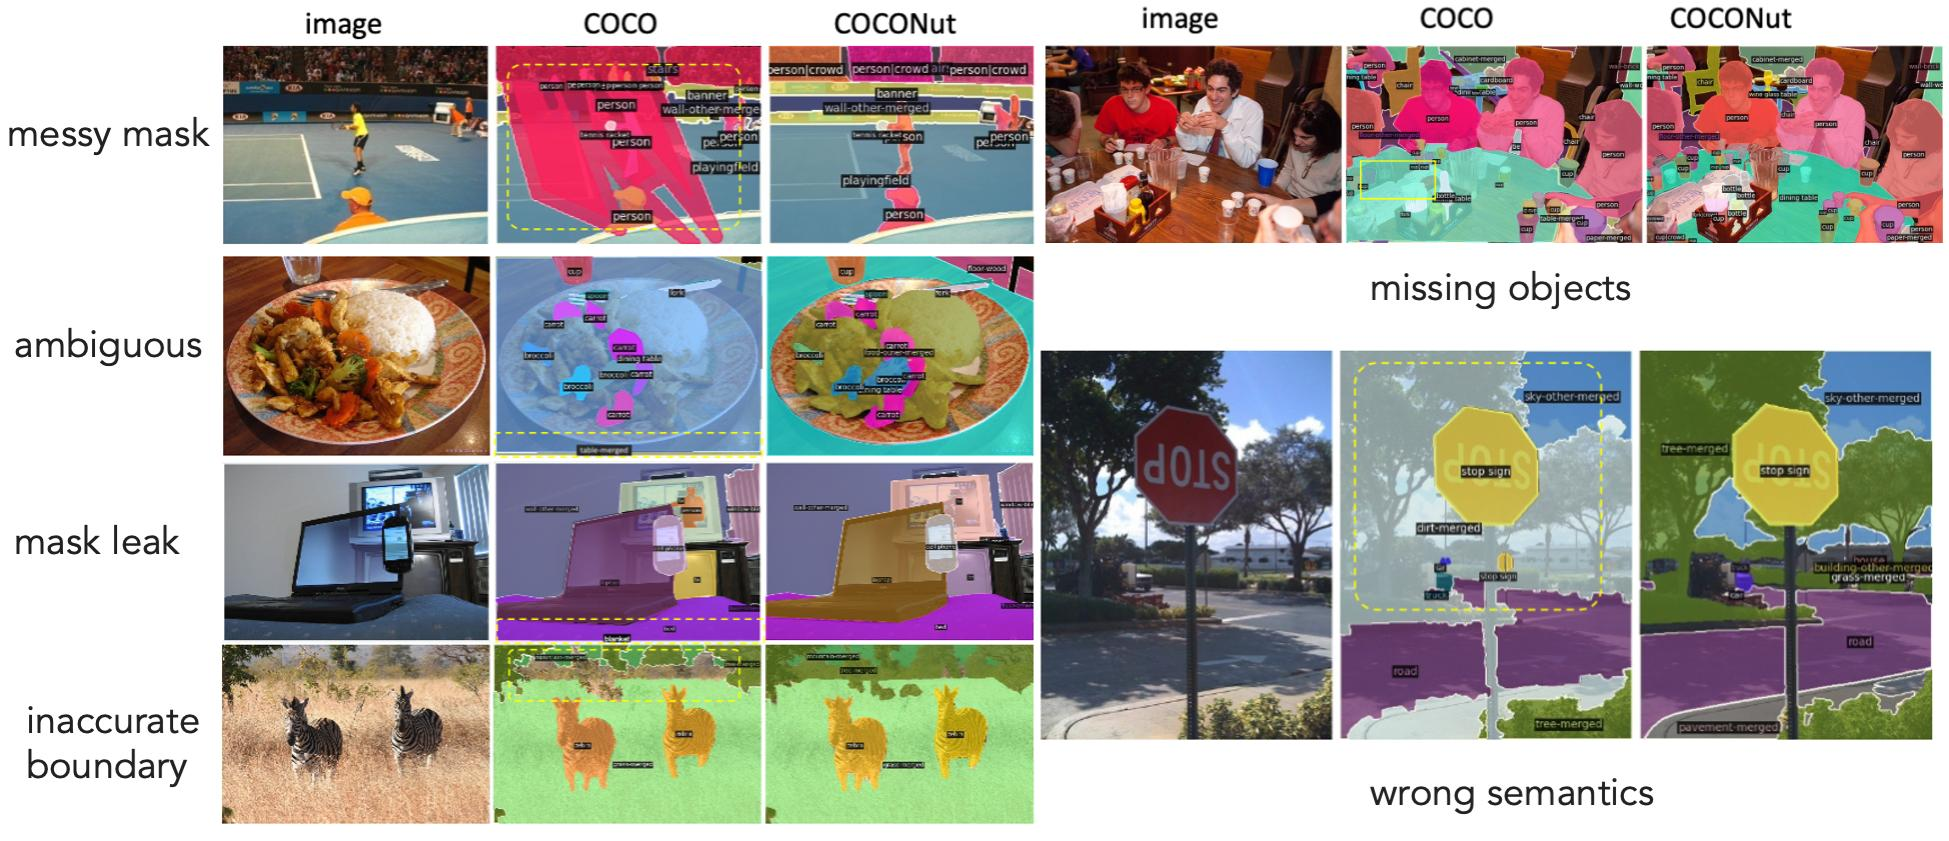

Annotations provide the **learning signal** for supervised computer vision.

If annotations are incorrect, the model receives incorrect targets.

### Common annotation problems

#### Wrong Class

```text
Actual → Car
Annotation → Dog
```

#### Missing Object

```text
Image → Car + Car
Annotation → Only one Car
```

#### Incorrect Bounding Box

The bounding box may:

- Exclude part of the object
- Include excessive background
- Be shifted
- Be assigned to the wrong object

#### Incorrect Mask

A segmentation mask may contain:

- Missing object pixels
- Extra background pixels
- Incorrect boundaries

### Why annotation quality matters

```text
Image
  +
Correct Annotation
  ↓
Useful Learning Signal
```

Whereas:

```text
Image
  +
Incorrect Annotation
  ↓
Incorrect Learning Signal
```

> **Poor annotations can directly limit model performance.**

---

## 9. Typical Vision Dataset Structure

A dataset may conceptually contain:

```text
vision_dataset/
│
├── images/
│   ├── image_001.jpg
│   ├── image_002.jpg
│   └── ...
│
├── labels/
│   ├── image_001.txt
│   ├── image_002.txt
│   └── ...
│
├── masks/
│   ├── image_001.png
│   ├── image_002.png
│   └── ...
│
└── splits/
    ├── train
    ├── validation
    └── test
```

> The exact directory structure depends on the dataset and annotation format.

---

## 10. Complete Mental Model

```text
                 VISION DATASET
                       │
             ┌─────────┴─────────┐
             ↓                   ↓
          Images             Annotations
                                 │
                  ┌──────────────┼──────────────┐
                  ↓              ↓              ↓
               Labels     Bounding Boxes      Masks
                  ↓              ↓              ↓
           Classification    Detection    Segmentation


                 Dataset Splitting
                       │
             ┌─────────┼─────────┐
             ↓         ↓         ↓
          Training  Validation   Test
```

### Dataset Quality

```text
Class Distribution
        ↓
Class Imbalance

Annotation Correctness
        ↓
Annotation Quality
```

---

## Must Know ⭐

- Images = visual input.
- Labels = class information.
- Bounding boxes = object location.
- Masks = pixel-level object/region information.
- Train set = learning.
- Validation set = development/tuning.
- Test set = final evaluation.
- Class imbalance can bias models and make accuracy misleading.
- Annotation quality directly affects supervised learning.

## Interview Points 🎯

**Q: What is the difference between classification and detection?**

> Classification predicts what is present; detection predicts what is present **and where it is**.

**Q: Why do we need a validation set?**

> To make model-development decisions without using the final test set.

**Q: Why can accuracy be misleading for imbalanced data?**

> A model can achieve high accuracy by predicting the majority class while performing poorly on the minority class.

**Q: What is the difference between a bounding box and a segmentation mask?**

> A bounding box gives a rectangular localization of an object, while a segmentation mask identifies the pixels belonging to the object or region.

## Final Mental Model

```text
Images
   ↓
Annotations
   ├── Labels
   ├── Bounding Boxes
   └── Masks
   ↓
Train / Validation / Test
   ↓
Model Training & Evaluation
   ↓
Check:
• Class imbalance
• Annotation quality
• Generalization
```

---